# Bus route simulation

Build a bus network, find the fastest route, close the Hospital, and find a new route.
Run the cells from top to bottom. All data is included here; no CSVs are needed.

The example uses fictional roads and fixed traffic. Express service can skip stops.
Start-terminal boarding and final-terminal unloading are excluded from the trip.

## 1. Import packages and choose the simulation settings

Stop 1 is the Residential Terminal, stop 12 is the Airport, and stop 7 is the Hospital.
If needed, install the packages once using `pip install networkx matplotlib`.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

START_STOP = 1
END_STOP = 12
CLOSED_STOP = 7
NORMAL_SPEED_KMH = 30

## 2. Enter the stops and roads

Each stop has an ID, a name, a stopping time, and a drawing position.
Each road has a starting stop, an ending stop, a distance, and a traffic multiplier.
For example, a traffic multiplier of 1.5 makes driving take 50% longer.
Drawing positions are not geographic coordinates and do not determine road lengths.

In [8]:
stops = [
    {"id": 1, "name": 'Residential Terminal', "stop_minutes": 0, "position": (0, 3)},
    {"id": 2, "name": 'Oak Street', "stop_minutes": 1, "position": (1.7, 3)},
    {"id": 3, "name": 'Elementary School', "stop_minutes": 2, "position": (3.4, 3)},
    {"id": 4, "name": 'Shopping Center', "stop_minutes": 3, "position": (5.1, 3)},
    {"id": 5, "name": 'University', "stop_minutes": 4, "position": (6.8, 3)},
    {"id": 6, "name": 'Downtown Station', "stop_minutes": 5, "position": (8.5, 3)},
    {"id": 7, "name": 'Hospital', "stop_minutes": 3, "position": (6.8, 1)},
    {"id": 8, "name": 'Business District', "stop_minutes": 2, "position": (5.1, 1)},
    {"id": 9, "name": 'Sports Complex', "stop_minutes": 2, "position": (3.4, 1)},
    {"id": 10, "name": 'Industrial Park', "stop_minutes": 1, "position": (1.7, 1)},
    {"id": 11, "name": 'Airport Hotel', "stop_minutes": 2, "position": (1.7, -1)},
    {"id": 12, "name": 'Airport Terminal', "stop_minutes": 0, "position": (6.8, -1)},
]

roads = [
    {"start": 1, "end": 2, "distance_km": 1.2, "traffic_multiplier": 1.1},
    {"start": 2, "end": 3, "distance_km": 0.8, "traffic_multiplier": 1.5},
    {"start": 3, "end": 4, "distance_km": 1.5, "traffic_multiplier": 1.3},
    {"start": 4, "end": 5, "distance_km": 2.0, "traffic_multiplier": 1.4},
    {"start": 5, "end": 6, "distance_km": 1.8, "traffic_multiplier": 2.0},
    {"start": 6, "end": 7, "distance_km": 1.0, "traffic_multiplier": 1.8},
    {"start": 7, "end": 8, "distance_km": 1.4, "traffic_multiplier": 1.6},
    {"start": 8, "end": 9, "distance_km": 2.2, "traffic_multiplier": 1.2},
    {"start": 9, "end": 10, "distance_km": 2.8, "traffic_multiplier": 1.1},
    {"start": 10, "end": 11, "distance_km": 3.0, "traffic_multiplier": 1.3},
    {"start": 11, "end": 12, "distance_km": 1.5, "traffic_multiplier": 1.5},
    {"start": 4, "end": 7, "distance_km": 6.0, "traffic_multiplier": 1.1},
    {"start": 6, "end": 9, "distance_km": 4.5, "traffic_multiplier": 1.0},
    {"start": 9, "end": 12, "distance_km": 8.0, "traffic_multiplier": 1.0},
]

## 3. Build the network and calculate road times

Road time = driving time with traffic + time spent at the arriving stop.
Adding the arriving stop time here means it is counted once along a route.
Each road's direction matters: a road from 4 to 7 does not automatically allow travel from 7 to 4.

In [3]:
def build_network(stops, roads, normal_speed_kmh):
    network = nx.DiGraph()

    # Add each bus stop and its information.
    for stop in stops:
        network.add_node(
            stop['id'],
            name=stop['name'],
            stop_minutes=stop['stop_minutes'],
            position=stop['position']
        )

    # Add each road, with a total time measured in minutes.
    for road in roads:
        start_stop = road['start']
        end_stop = road['end']
        distance_km = road['distance_km']
        traffic_multiplier = road['traffic_multiplier']

        normal_driving_hours = distance_km / normal_speed_kmh
        normal_driving_minutes = normal_driving_hours * 60
        driving_minutes = normal_driving_minutes * traffic_multiplier
        stopping_minutes = network.nodes[end_stop]['stop_minutes']
        total_minutes = driving_minutes + stopping_minutes

        network.add_edge(
            start_stop,
            end_stop,
            distance_km=distance_km,
            traffic_multiplier=traffic_multiplier,
            driving_minutes=driving_minutes,
            minutes=total_minutes
        )

    return network


network = build_network(stops, roads, NORMAL_SPEED_KMH)
print('Number of stops:', network.number_of_nodes())
print('Number of roads:', network.number_of_edges())

Number of stops: 12
Number of roads: 14


### Time formula

$$
\boxed{
T =
\underbrace{\frac{d}{v}\times60\times m}_{\text{Driving time with traffic}}
+
\underbrace{s}_{\text{Time at the arriving stop}}
}
$$

All times are in **minutes**. Here, $d$ is road distance in km, $v=30$ km/h is the normal speed, $m$ is the traffic multiplier, and $s$ is the arriving stop's stopping time.

**Example — Shopping Center to Hospital:**

$$
T=\frac{6}{30}\times60\times1.1+3=\boxed{16.2\text{ min}}
$$

## 4. Find the original fastest route

NetworkX finds the route with the lowest total `minutes`.
The loop then adds each road's time to calculate the whole trip time.

In [4]:
def find_fastest_route(network, start_stop, end_stop):
    route = nx.shortest_path(
        network,
        source=start_stop,
        target=end_stop,
        weight='minutes'
    )

    total_minutes = 0

    for route_index in range(len(route) - 1):
        current_stop = route[route_index]
        next_stop = route[route_index + 1]
        road_minutes = network[current_stop][next_stop]['minutes']
        total_minutes = total_minutes + road_minutes

    return route, total_minutes


original_route, original_minutes = find_fastest_route(network, START_STOP, END_STOP)
print('Original route:', original_route)
print(f'Total time: {original_minutes:.1f} min')

Original route: [1, 2, 3, 4, 7, 8, 9, 12]
Total time: 60.9 min


## 5. Define the drawing functions

These functions only draw the network; they do not change its route costs.
`draw_roads` draws arrows and minute labels. `draw_stops` draws circles and stop names.
`show_map` combines them into one image.

Blue shows the fastest route. Gray shows other roads and stops. Red marks a closed stop.
Road labels already include the arriving stop time, so do not add it again.
Crossings without nodes are not connections.

In [5]:
def draw_roads(network, route, positions, axes):
    # List the roads used by the selected route.
    route_roads = []
    for route_index in range(len(route) - 1):
        start_stop = route[route_index]
        end_stop = route[route_index + 1]
        route_roads.append((start_stop, end_stop))

    for start_stop, end_stop, road in network.edges(data=True):
        if (start_stop, end_stop) in route_roads:
            road_color = '#176BB0'
            line_width = 2.8
        else:
            road_color = '#B4BEC9'
            line_width = 1.3

        # Curve the downtown shortcut so it is easier to see.
        if start_stop == 6 and end_stop == 9:
            curve = 0.5
            label_offset = 2.0
        else:
            curve = 0
            label_offset = 0.15

        arrow = FancyArrowPatch(
            positions[start_stop],
            positions[end_stop],
            arrowstyle='-|>',
            mutation_scale=13,
            color=road_color,
            linewidth=line_width,
            shrinkA=15,
            shrinkB=15,
            connectionstyle=f'arc3,rad={curve}'
        )
        axes.add_patch(arrow)

        start_x, start_y = positions[start_stop]
        end_x, end_y = positions[end_stop]
        label_x = (start_x + end_x) / 2
        label_y = (start_y + end_y) / 2 + label_offset
        time_label = f"{road['minutes']:.1f} min"

        axes.text(
            label_x, label_y, time_label,
            ha='center', fontsize=8, color=road_color,
            bbox=dict(facecolor='white', edgecolor='none', pad=1)
        )


def draw_stops(original_network, available_network, route, positions, axes):
    # Use the original stops so the closed Hospital can still be shown in red.
    for stop_id, stop in original_network.nodes(data=True):
        x, y = positions[stop_id]

        if stop_id not in available_network:
            stop_color = '#C23B46'
            status_label = 'CLOSED'
        else:
            status_label = f"{stop['stop_minutes']} min stop"
            if stop_id in route:
                stop_color = '#176BB0'
            else:
                stop_color = '#79899A'

        axes.scatter(x, y, s=430, color=stop_color, zorder=3)
        axes.text(
            x, y, str(stop_id),
            ha='center', va='center', color='white', fontsize=9
        )

        # Place stop names where they do not cover nearby roads.
        label_x = x
        if stop_id == 10:
            label_x = x - 0.65
            label_y = y
        elif y == 3:
            label_y = y + 0.55
        else:
            label_y = y - 0.65

        stop_label = stop['name'] + '\n' + status_label
        axes.text(
            label_x, label_y, stop_label,
            ha='center', fontsize=9, color=stop_color,
            bbox=dict(facecolor='white', edgecolor='none', pad=1)
        )


def show_map(available_network, original_network, route, title, filename):
    figure, axes = plt.subplots(figsize=(12, 7))

    positions = {}
    for stop_id, stop in original_network.nodes(data=True):
        positions[stop_id] = stop['position']

    draw_roads(available_network, route, positions, axes)
    draw_stops(original_network, available_network, route, positions, axes)

    axes.set_title(title, fontsize=16, fontweight='bold', pad=14)
    axes.set_xlim(-0.8, 9.3)
    axes.set_ylim(-2, 4.7)
    axes.axis('off')

    figure.tight_layout()
    figure.savefig(filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(figure)

## 6. Show the original route

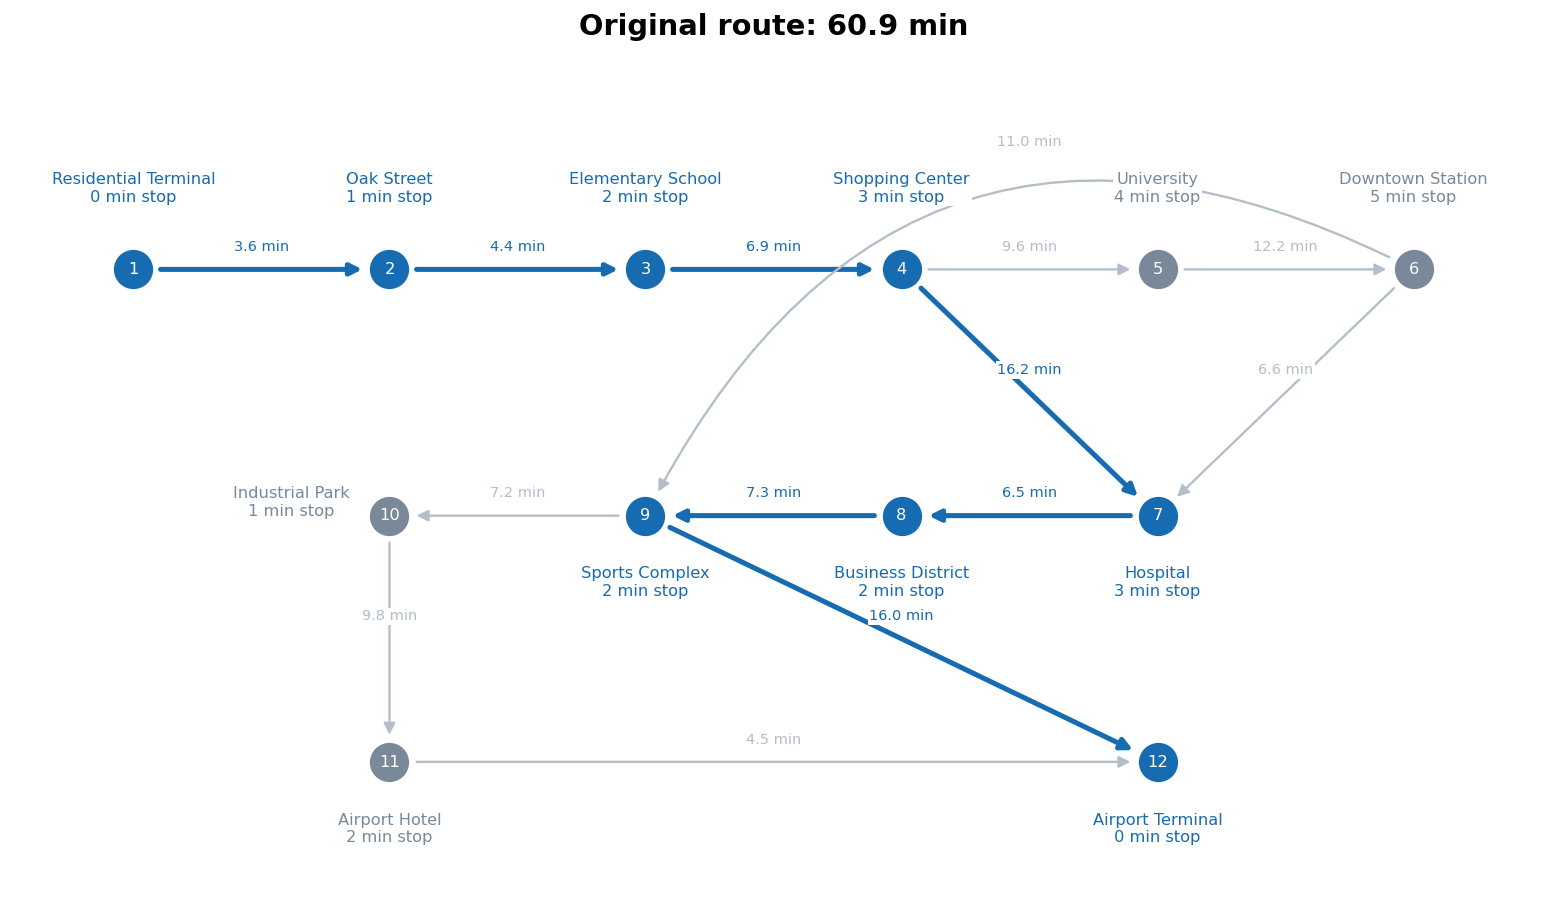

In [6]:
original_title = f'Original route: {original_minutes:.1f} min'

show_map(
    network,
    network,
    original_route,
    original_title,
    'original_route.png'
)

## 7. Close the Hospital and find the new route

Make a copy to preserve the original network. Removing stop 7 also removes the roads
entering and leaving it. This assumes the location is impassable, not merely closed to boarding.

In [7]:
disrupted_network = network.copy()
disrupted_network.remove_node(CLOSED_STOP)

new_route, new_minutes = find_fastest_route(disrupted_network, START_STOP, END_STOP)

print('Closed stop:', network.nodes[CLOSED_STOP]['name'])
print('New route:', new_route)
print(f'Total time: {new_minutes:.1f} min')

Closed stop: Hospital
New route: [1, 2, 3, 4, 5, 6, 9, 12]
Total time: 63.7 min


## 8. Show the route after closure

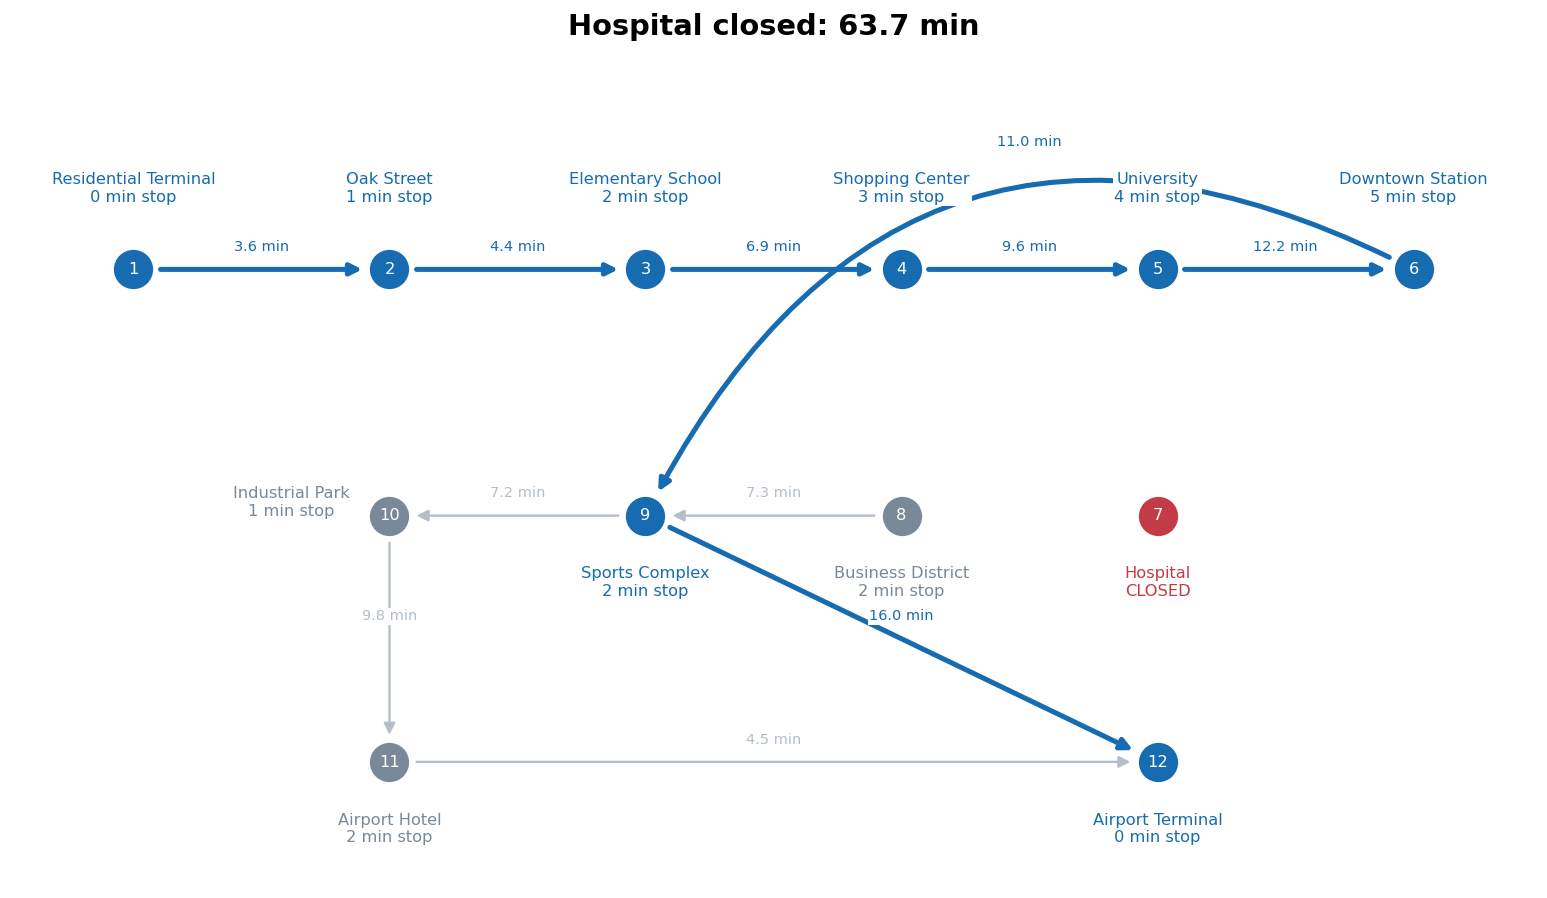

In [8]:
new_title = f'Hospital closed: {new_minutes:.1f} min'

show_map(
    disrupted_network,
    network,
    new_route,
    new_title,
    'hospital_closed_route.png'
)

## 9. Compare the travel times

In [9]:
additional_minutes = new_minutes - original_minutes

print(f'Original trip: {original_minutes:.1f} min')
print(f'After closure: {new_minutes:.1f} min')
print(f'Additional time: {additional_minutes:.1f} min')

Original trip: 60.9 min
After closure: 63.7 min
Additional time: 2.8 min
